# 02 · EDA do preço por m²

**Projeto:** Apex Imóveis — priorização de segmentos residenciais para um piloto de prospecção.

**Pergunta central do contrato:** quais segmentos de apartamentos apresentam atividade transacional recorrente e preços de referência confiáveis, mesmo depois de corrigir inflação e composição?

**Este notebook responde, em ordem:**
1. Como é a distribuição do R$/m²? Os valores extremos são erro?
2. Como o preço evolui no tempo, em valores nominais e reais?
3. A composição do que se vende mudou?
4. Dentro de cada tipo de apartamento, o preço real subiu?

> **[NOTEBOOK]** porque aqui o objetivo é *olhar* os dados para pensar. As regras já estão no SQL.

**Ressalva importante:** o R$/m² usa a **área construída**, que inclui parte das áreas comuns do condomínio. Serve para comparar segmentos entre si, mas não é o R$/m² dos anúncios.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_colwidth", None)

candidatos = [Path.cwd(), *Path.cwd().parents]
raiz = next((p for p in candidatos if (p / "src" / "database.py").exists()), None)
assert raiz is not None, f"Não achei src/database.py a partir de {Path.cwd()}. O notebook está dentro de apex-imoveis?"
sys.path.append(str(raiz / "src"))

from database import get_engine

engine = get_engine()


def consulta(sql: str) -> pd.DataFrame:
    """Roda um SELECT no banco e devolve um DataFrame"""
    return pd.read_sql(sql, engine)


def milhar(n) -> str:
    """12345 -> '12.345' (Deixando em formato BR)"""
    return f"{n:,.0f}".replace(",", ".")


def eixo_milhar(ax, eixo="y"):
    """Põe separador de milhar brasileiro no eixo do gráfico"""
    formatador = FuncFormatter(lambda v, _: milhar(v))
    (ax.yaxis if eixo == "y" else ax.xaxis).set_major_formatter(formatador)

## 1. Carregar o recorte

Vamos ler a view `vw_apto_recorte` **uma vez** e fazer a análise no pandas. Duas escolhas:

- **Só as colunas necessárias**, sem `sql` nem endereço: a EDA não precisa identificar imóveis.
- **Só a janela de análise** (jan/2022 a nov/2025, por data da transação) e linhas com deflator.

In [11]:
df = consulta("""
    SELECT data_transacao, mes_transacao, ano_transacao, setor_fiscal,
           area_construida, ano_conclusao, padrao_cod,
           valor_transacao, preco_m2_nominal, preco_m2_real
    FROM analytics.vw_apto_recorte
    WHERE na_janela_analise AND NOT sem_deflator
""")
df["data_transacao"] = pd.to_datetime(df["data_transacao"])
df["mes_transacao"] = pd.to_datetime(df["mes_transacao"])
for col in ["area_construida", "valor_transacao", "preco_m2_nominal", "preco_m2_real"]:
    df[col] = df[col].astype(float)

print(f"{milhar(len(df))} linhas | {df['setor_fiscal'].nunique()} setores | "
      f"de {df['mes_transacao'].min():%m/%Y} a {df['mes_transacao'].max():%m/%Y}")
df.dtypes

222.295 linhas | 236 setores | de 01/2022 a 11/2025


data_transacao      datetime64[ns]
mes_transacao       datetime64[ns]
ano_transacao                int64
setor_fiscal                object
area_construida            float64
ano_conclusao              float64
padrao_cod                   int64
valor_transacao            float64
preco_m2_nominal           float64
preco_m2_real              float64
dtype: object

## 2. Distribuição do preço por m² e valores extremos

A média é puxada por poucos valores muito altos. Em dados de imóveis, a distribuição é **assimétrica**, então vamos usar a **mediana** e os percentis como medidas principais.

In [13]:
percentis = [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
resumo = df["preco_m2_nominal"].describe(percentiles=percentis)

tabela = pd.DataFrame({"R$/m² nominal": resumo.map(milhar)})
tabela

,R$/m² nominal
count,222.295
mean,5.000
std,2.737
min,18
0.1%,314
1%,784
5%,1.939
25%,3.291
50%,4.495
75%,6.095


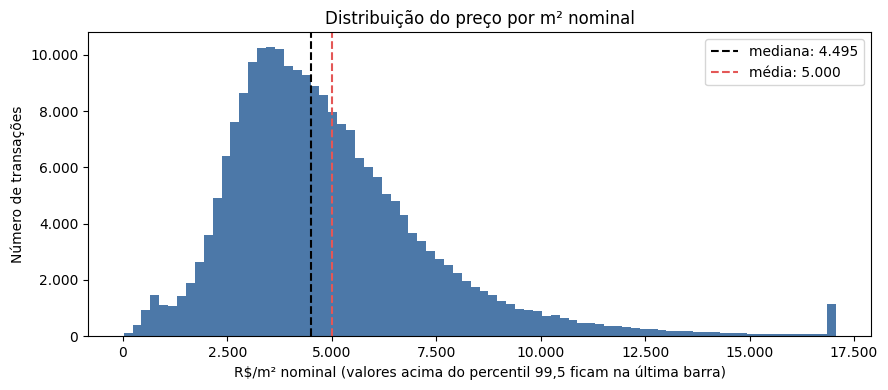

In [14]:
mediana = df["preco_m2_nominal"].median()
media = df["preco_m2_nominal"].mean()
corte = df["preco_m2_nominal"].quantile(0.995)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df["preco_m2_nominal"].clip(upper=corte), bins=80, color="#4C78A8")
ax.axvline(mediana, color="black", linestyle="--", label=f"mediana: {milhar(mediana)}")
ax.axvline(media, color="#E45756", linestyle="--", label=f"média: {milhar(media)}")
eixo_milhar(ax, "x")
eixo_milhar(ax, "y")
ax.set_xlabel("R$/m² nominal (valores acima do percentil 99,5 ficam na última barra)")
ax.set_ylabel("Número de transações")
ax.set_title("Distribuição do preço por m² nominal")
ax.legend()
plt.tight_layout()
plt.show()

In [15]:
baixo = df["preco_m2_nominal"] < 1_000
alto = df["preco_m2_nominal"] > 20_000
grupos = {"abaixo de R$ 1.000/m²": baixo, "acima de R$ 20.000/m²": alto, "demais": ~(baixo | alto)}

extremos = pd.DataFrame(
    {
        nome: {
            "transações": mascara.sum(),
            "área mediana (m²)": df.loc[mascara, "area_construida"].median(),
            "valor mediano (R$)": df.loc[mascara, "valor_transacao"].median(),
        }
        for nome, mascara in grupos.items()
    }
).T
extremos.map(milhar)

,transações,área mediana (m²),valor mediano (R$)
abaixo de R$ 1.000/m²,3.614,108,70.309
acima de R$ 20.000/m²,635,449,10.600.000
demais,218.046,105,435.000


## 3. Evolução no tempo: nominal versus real

O valor **nominal** é o que foi declarado, em reais do dia. O **real** corrige tudo para **reais de dez/2025** pelo IPCA. Se os dois subissem juntos, não haveria valorização real: seria só inflação.

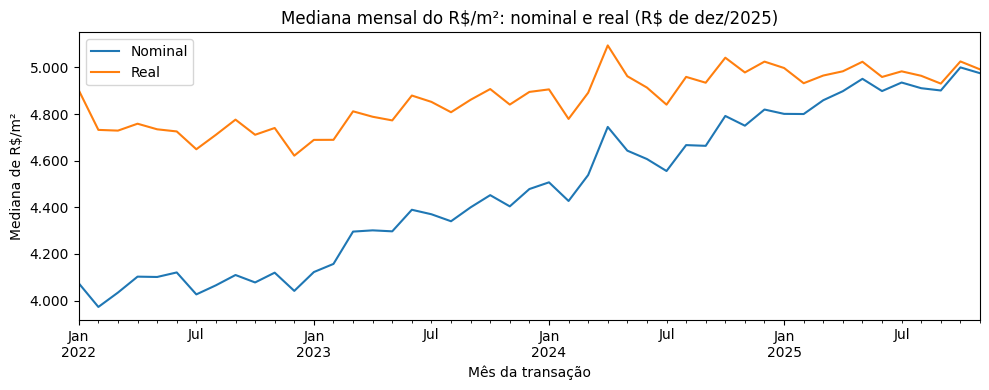

In [16]:
mensal = df.groupby("mes_transacao").agg(
    transacoes=("preco_m2_nominal", "size"),
    nominal=("preco_m2_nominal", "median"),
    real=("preco_m2_real", "median"),
)

ax = mensal[["nominal", "real"]].plot(figsize=(10, 4))
eixo_milhar(ax)
ax.set_ylabel("Mediana de R$/m²")
ax.set_xlabel("Mês da transação")
ax.set_title(r"Mediana mensal do R\$/m²: nominal e real (R\$ de dez/2025)")
ax.legend(["Nominal", "Real"])
plt.tight_layout()
plt.show()

In [18]:
anual = df.groupby("ano_transacao").agg(
    transacoes=("preco_m2_nominal", "size"),
    nominal=("preco_m2_nominal", "median"),
    real=("preco_m2_real", "median"),
)
anual["variacao_nominal"] = (anual["nominal"] / anual["nominal"].iloc[0] - 1) * 100
anual["variacao_real"] = (anual["real"] / anual["real"].iloc[0] - 1) * 100

vista = anual.copy()
for col in ["transacoes", "nominal", "real"]:
    vista[col] = vista[col].map(milhar)
for col in ["variacao_nominal", "variacao_real"]:
    vista[col] = vista[col].map(lambda x: f"{x:+.1f}%")
vista

,transacoes,nominal,real,variacao_nominal,variacao_real
ano_transacao,,,,,
2022,52.119,4.070,4.729,+0.0%,+0.0%
2023,51.361,4.344,4.822,+6.7%,+2.0%
2024,61.159,4.653,4.949,+14.3%,+4.7%
2025,57.656,4.902,4.977,+20.4%,+5.2%


In [20]:
sem_extremos = df[~(baixo | alto)]

comparacao_extremos = pd.DataFrame({
    "todas": df.groupby("ano_transacao")["preco_m2_real"].median(),
    "sem extremos": sem_extremos.groupby("ano_transacao")["preco_m2_real"].median(),
})

for nome in comparacao_extremos.columns:
    serie = comparacao_extremos[nome]
    print(f"{nome:<14} variação real {serie.index[0]}→{serie.index[-1]}: {(serie.iloc[-1] / serie.iloc[0] - 1) * 100:+.1f}%")

todas          variação real 2022→2025: +5.2%
sem extremos   variação real 2022→2025: +4.4%


## 4. A composição do que se vende mudou?

A mediana do R$/m² de um ano mistura apartamentos de tamanhos diferentes. Se, de um ano para o outro, passam a ser vendidos mais apartamentos pequenos, e os pequenos custam mais por m², a mediana sobe **sem que nenhum imóvel tenha valorizado**. Isso é o efeito de **composição**.

Vamos agrupar os apartamentos em **faixas de área construída** e ver se a participação de cada faixa mudou.

In [21]:
limites = [0, 50, 80, 120, 200, float("inf")]
nomes = ["até 50", "50–80", "80–120", "120–200", "acima de 200"]
df["faixa_area"] = pd.cut(df["area_construida"], bins=limites, labels=nomes)

participacao = pd.crosstab(df["faixa_area"], df["ano_transacao"], normalize="columns") * 100
participacao.round(1)

ano_transacao,2022,2023,2024,2025
faixa_area,,,,
até 50,7.0,8.6,10.3,13.2
50–80,18.1,18.0,17.8,18.5
80–120,35.6,34.2,34.2,32.2
120–200,24.3,24.0,23.4,22.6
acima de 200,15.0,15.2,14.2,13.5


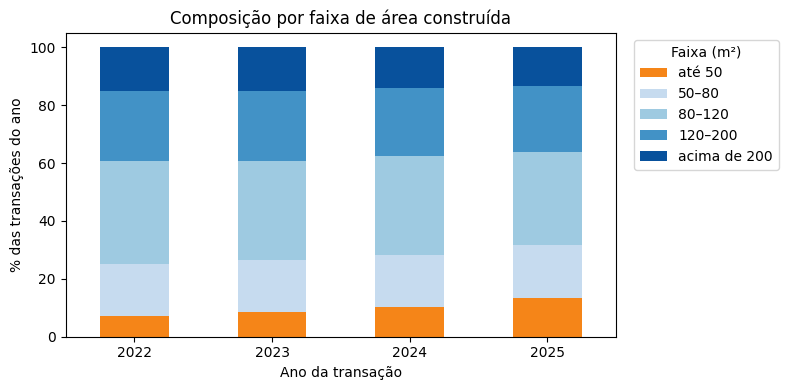

In [22]:
cores = ["#F58518", "#C6DBEF", "#9ECAE1", "#4292C6", "#08519C"] 
ax = participacao.T.plot(kind="bar", stacked=True, figsize=(8, 4), color=cores)
ax.set_ylabel("% das transações do ano")
ax.set_xlabel("Ano da transação")
ax.set_title("Composição por faixa de área construída")
ax.legend(title="Faixa (m²)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Por que a composição importa? E dentro de cada faixa, o preço subiu?

Primeiro, quanto custa o m² em cada faixa. Depois, o que aconteceu **dentro** de cada faixa ao longo dos anos. Comparar apartamentos parecidos entre si é a forma de separar valorização de mudança de mix.

In [23]:
preco_faixa = df.groupby("faixa_area", observed=True)["preco_m2_real"].median()

tabela_faixa = pd.DataFrame({"mediana R$/ m² real": preco_faixa.map(milhar)})
tabela_faixa

,mediana R$/ m² real
faixa_area,
até 50,6.239
50–80,4.612
80–120,4.188
120–200,5.155
acima de 200,6.128


In [25]:
mediana_real = (
    df.groupby(["faixa_area", "ano_transacao"], observed=True)["preco_m2_real"].median().unstack()
)
primeiro, ultimo = mediana_real.columns[0], mediana_real.columns[-1]
variacao_faixa = (mediana_real[ultimo] / mediana_real[primeiro] - 1) * 100

vista_faixa = mediana_real.map(milhar)
vista_faixa["variacao"] = variacao_faixa.map(lambda x: f"{x:+.1f}%")
vista_faixa

ano_transacao,2022,2023,2024,2025,variacao
faixa_area,,,,,
até 50,5.938,6.012,6.349,6.511,+9.7%
50–80,4.611,4.546,4.666,4.613,+0.0%
80–120,4.127,4.169,4.234,4.232,+2.5%
120–200,5.064,5.150,5.198,5.205,+2.8%
acima de 200,5.914,6.093,6.281,6.203,+4.9%


## 6. Primeira estimativa com composição fixa (preliminar)

A ideia: calcular o preço de cada ano **com os mesmos pesos de faixa em todos os anos**. Se os pesos não mudam, a mudança do índice só pode vir de variação de preço dentro das faixas, e não de mudança de mix.

Os pesos podem ser os do primeiro ano ou os do último. Os resultados diferem pouco, e a diferença é uma medida honesta da **incerteza** da escolha.

> Esta é uma estimativa **preliminar**: usa apenas cinco faixas de área e não controla a **localização**. O próximo notebook refina.

In [26]:
def indice_estratificado(pesos):
    pesos = pesos / pesos.sum()
    serie = mediana_real.mul(pesos, axis=0).sum()
    return serie / serie.iloc[0] * 100


comparacao = pd.DataFrame({
    "mediana simples": anual["real"] / anual["real"].iloc[0] * 100,
    "estratificado, pesos do 1º ano": indice_estratificado(participacao.iloc[:, 0]),
    "estratificado, pesos do último ano": indice_estratificado(participacao.iloc[:, -1]),
})
comparacao.round(1)

,mediana simples,"estratificado, pesos do 1º ano","estratificado, pesos do último ano"
ano_transacao,,,
2022,100.0,100.0,100.0
2023,102.0,101.2,101.1
2024,104.7,103.4,103.6
2025,105.2,103.2,103.7


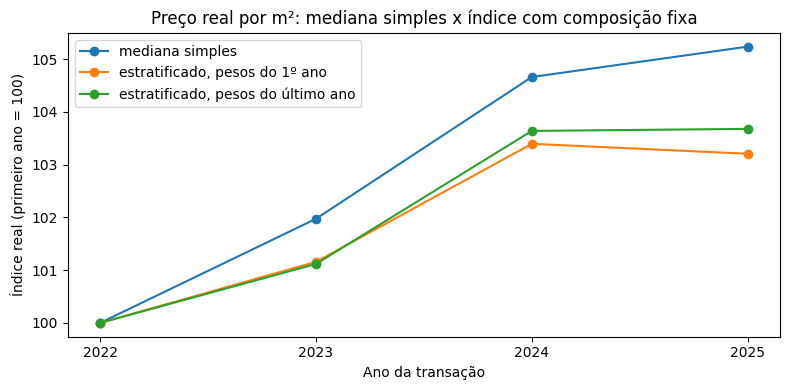

In [27]:
ax = comparacao.plot(marker="o", figsize=(8, 4))
ax.set_ylabel("Índice real (primeiro ano = 100)")
ax.set_xlabel("Ano da transação")
ax.set_xticks(list(comparacao.index))
ax.set_title("Preço real por m²: mediana simples x índice com composição fixa")
plt.tight_layout()
plt.show()